Ticket: https://open-jira.nrao.edu/browse/PIPE-2936

I ran into numerical differences between the CASA measures and astropy coordinate transformation implementations. In this notebook, I'm trying to figure out how to get them to align.

In [1]:
from pipeline.infrastructure import casa_tools

2026-06-05 08:37:58 INFO: Pipeline version 2026.1.1.45+7-g2db91ce3e-PIPE-2936 running on eddington.desktop.astro.rug.nl
2026-06-05 08:37:58 INFO: Host environment:
	CPU: Intel(R) Core(TM) i7-14700T (physical cores: 20, logical cores: 28)
	Memory: 30.7 GiB RAM, unknown swap
	OS: Rocky Linux 9.7 (Blue Onyx)
	cgroup limits: N/A of 28 CPU cores, memory limits=N/A
	ulimit limits: CPU time=N/A, memory=N/A, files=4096
2026-06-05 08:37:58 INFO: Environment as detected by CASA:
	CPUs reported by CASA: 28 cores, max 28 OpenMP threads
	Available memory: 30.7 GiB


We'll first try to recreate the values for measurementset.py's `compute_az_el_to_field()`.

In [2]:
from unittest.mock import Mock

In [3]:
# realistic input data for casa_tools.measures (taken from a pipeline run on real ASDM)
field = Mock()
field.mdirection = {
    'm0': {'unit': 'rad', 'value': -1.2005642899794717},
    'm1': {'unit': 'rad', 'value': -0.5103639490189864},
    'refer': 'ICRS',
    'type': 'direction',
}
epoch = {'m0': {'unit': 'd', 'value': 60462.40586666667}, 'refer': 'UTC', 'type': 'epoch'}

In [4]:
me = casa_tools.measures

In [5]:
me is casa_tools.measures

True

In [6]:
me.doframe(epoch)

True

What does this do? The documentation of this function is indecipherable... 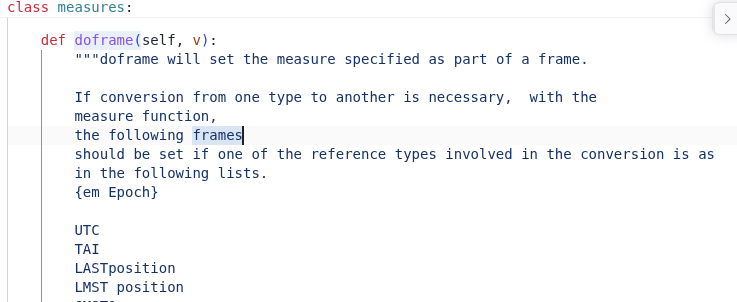

It leads into compiled CASA C functions, so the source is also hard to trace from a Python IDE (at least in VSCode).

In [7]:
me.epoch()

{'m0': {'unit': 'd', 'value': 0.0}, 'refer': 'UTC', 'type': 'epoch'}

... alright, so it doesn't set things there I guess...

In [8]:
me.doframe(epoch)

True

Alright, after some thought, what I think `doframe` is saying is that if you want to use `measures` for coordinate system transformation (which we do) you need to provide it with some parameters. Why, oh, why it uses such a complex mechanism and obscure language to pass parameters is still unclear, but at least the terms are clear. Frame refers to the reference frame for the coordinates you put in, which indeed depends on lots of input, like the exact time (epoch), and also the system (e.g. WGS84 that defines an earth-centric lat/long/alt frame).

In [9]:
from pipeline.domain.measurementset import MeasurementSet

In [10]:
ms = Mock(spec=MeasurementSet)
ms.antenna_array = Mock()
ms.antenna_array.name = 'ALMA'

In [11]:
me.observatory(ms.antenna_array.name)

{'m0': {'unit': 'rad', 'value': -1.1825465955049892},
 'm1': {'unit': 'rad', 'value': -0.4018251640113072},
 'm2': {'unit': 'm', 'value': 5056.8},
 'refer': 'WGS84',
 'type': 'position'}

What happens when you give it a different epoch here?

In [12]:
me.doframe(me.epoch())

True

In [13]:
me.observatory(ms.antenna_array.name)

{'m0': {'unit': 'rad', 'value': -1.1825465955049892},
 'm1': {'unit': 'rad', 'value': -0.4018251640113072},
 'm2': {'unit': 'm', 'value': 5056.8},
 'refer': 'WGS84',
 'type': 'position'}

No change, ok...

In [14]:
me.doframe(epoch)

True

In [15]:
me.doframe(me.observatory(ms.antenna_array.name))

True

In [16]:
me.measure(field.mdirection, 'AZELGEO')

{'m0': {'unit': 'rad', 'value': -1.8943527849948039},
 'm1': {'unit': 'rad', 'value': 0.9815369865505564},
 'refer': 'AZELGEO',
 'type': 'direction'}

Is CASA deterministic in converting back and forth btw?

In [17]:
forth = me.measure(field.mdirection, 'AZELGEO')
back = me.measure(forth, "ICRS")

In [18]:
back, field.mdirection

({'m0': {'unit': 'rad', 'value': -1.200564289980747},
  'm1': {'unit': 'rad', 'value': -0.5103639490190213},
  'refer': 'ICRS',
  'type': 'direction'},
 {'m0': {'unit': 'rad', 'value': -1.2005642899794717},
  'm1': {'unit': 'rad', 'value': -0.5103639490189864},
  'refer': 'ICRS',
  'type': 'direction'})

It is not, fun!

In [19]:
back_i = me.measure(forth, "ICRS")
for i in range(100):
    forth_i = me.measure(back_i, 'AZELGEO')
    back_i = me.measure(forth_i, "ICRS")

In [20]:
back_i['m0']['value'] - field.mdirection['m0']['value']

-1.2882539479619481e-10

In [21]:
for i in range(10000):
    forth_i = me.measure(back_i, 'AZELGEO')
    back_i = me.measure(forth_i, "ICRS")

In [22]:
back_i['m0']['value'] - field.mdirection['m0']['value']

-1.2883983879774519e-08

Oh, damn, it just drifts... Is this actually an error or does this function use a time-dependent frame and is that expected behavior?

Waited a few minutes, then trying another back and forth:

In [23]:
forth_j = me.measure(back_i, 'AZELGEO')
back_j = me.measure(forth_j, "ICRS")

In [24]:
back_j['m0']['value'] - back_i['m0']['value']

-1.2756462552943049e-12

Seems to scale almost perfectly with number of iterations, not time...

ALRIGHTY.

Let's see how astropy does things then, and see how we can reproduce CASA's behavior, while possibly also avoiding its pathologies.

In [25]:
from pipeline.infrastructure import utils

In [26]:
location = utils.get_observatory_location(ms.antenna_array.name)

In [27]:
location

<EarthLocation (2225122.39026944, -5440258.9852695, -2481007.63746283) m>

This uses a hard-coded value, what does the interweb-version say?

In [28]:
from astropy.coordinates import EarthLocation

In [29]:
EarthLocation.of_site(ms.antenna_array.name)

<EarthLocation (2225015.30883296, -5440016.41799762, -2481631.27428014) m>

Alright, different... 🙄

In [30]:
from astropy.time import Time

In [31]:
obs_time = Time(epoch['m0']['value'], format='mjd', scale='utc')

In [32]:
obs_time

<Time object: scale='utc' format='mjd' value=60462.40586666667>

In [33]:
epoch

{'m0': {'unit': 'd', 'value': 60462.40586666667},
 'refer': 'UTC',
 'type': 'epoch'}

Value preserved, good...

In [34]:
refer = field.mdirection['refer'].upper()
if refer in ('J2000', 'FK5'):
    frame = 'fk5'
else:
    frame = refer.lower()

In [35]:
frame

'icrs'

In [36]:
from astropy.coordinates import AltAz, SkyCoord

In [37]:
coords = SkyCoord(
    field.mdirection['m0']['value'],
    field.mdirection['m1']['value'],
    frame=frame,
    unit=(field.mdirection['m0']['unit'], field.mdirection['m1']['unit']),
)

In [38]:
coords

<SkyCoord (ICRS): (ra, dec) in deg
    (291.21273315, -29.24170029)>

In [39]:
field.mdirection

{'m0': {'unit': 'rad', 'value': -1.2005642899794717},
 'm1': {'unit': 'rad', 'value': -0.5103639490189864},
 'refer': 'ICRS',
 'type': 'direction'}

In [40]:
coords.ra.rad

np.float64(5.082621017200115)

In [41]:
import numpy as np

In [42]:
coords.ra.rad - 2*np.pi

np.float64(-1.2005642899794715)

Hmm, ok, also a slight deviation there, I guess that's inevitable with all the back and forth trigonometry...

In [43]:
coords.dec.rad

np.float64(-0.5103639490189864)

That one is perfect.

In [44]:
-1.2005642899794717 + 2*np.pi

5.082621017200115

In [45]:
-1.2005642899794717 + 2*np.pi - 2*np.pi

-1.2005642899794715

In [46]:
-1.2005642899794717 + 2*np.pi - 2*np.pi + 2*np.pi - 2*np.pi

-1.2005642899794715

At least this is a stable difference, not cumulative, just an unfortunate floating point value, I guess.

In [47]:
altaz_frame = AltAz(obstime=obs_time, location=location)
coords_altaz = coords.transform_to(altaz_frame)

In [48]:
coords_altaz

<SkyCoord (AltAz: obstime=60462.40586666667, location=(2225122.3902694373, -5440258.985269505, -2481007.637462835) m, pressure=0.0 hPa, temperature=0.0 deg_C, relative_humidity=0.0, obswl=1.0 micron): (az, alt) in deg
    (251.46153469, 56.23789623)>

Ok, so that's the one we want to compare against CASA.

In [49]:
myazel = me.measure(field.mdirection, 'AZELGEO')

In [50]:
myazel

{'m0': {'unit': 'rad', 'value': -1.8943527849948039},
 'm1': {'unit': 'rad', 'value': 0.9815369865505564},
 'refer': 'AZELGEO',
 'type': 'direction'}

In [51]:
myaz = myazel['m0']['value']
myel = myazel['m1']['value']
myaz = (myaz * 180 / np.pi) % 360
myel *= 180 / np.pi

In [52]:
myaz, myel

(251.46158051094426, 56.23792676533593)

How do AZEL and AZELGEO differ btw?

In [53]:
me.measure(field.mdirection, 'AZEL')

{'m0': {'unit': 'rad', 'value': -1.8977663370570124},
 'm1': {'unit': 'rad', 'value': 0.980766793173344},
 'refer': 'AZEL',
 'type': 'direction'}

In [78]:
location

<EarthLocation (2225122.39026944, -5440258.9852695, -2481007.63746283) m>

Let's compare locations in the same frame.

In [79]:
me.observatory(ms.antenna_array.name)

{'m0': {'unit': 'rad', 'value': -1.1825465955049892},
 'm1': {'unit': 'rad', 'value': -0.4018251640113072},
 'm2': {'unit': 'm', 'value': 5056.8},
 'refer': 'WGS84',
 'type': 'position'}

In [80]:
location.to_geodetic("WGS84")

GeodeticLocation(lon=<Longitude -67.754929 deg>, lat=<Latitude -23.022886 deg>, height=<Quantity 5000. m>)

Wow, exactly 5km, that's convenient! Also, wrong. Let's remove that hardcoded value then.

In [82]:
location.to_geodetic("WGS84").lon.rad, location.to_geodetic("WGS84").lat.rad

(np.float64(-1.1825465955049892), np.float64(-0.4018251640113071))

Those are actually spot on! Just a height correction then. And what is the online-retrieved one?

In [83]:
EarthLocation.of_site(ms.antenna_array.name).to_geodetic("WGS84")

GeodeticLocation(lon=<Longitude -67.755 deg>, lat=<Latitude -23.029 deg>, height=<Quantity 5000. m>)

So weird. So I guess we do need hardcoded values, at least to reproduce the old values for now. Then later people can fix the astropy retrieved value or choose to work with it in the pipeline after all. Because, btw, who says CASA is correct here?

In [86]:
good_location = EarthLocation.from_geodetic(-1.1825465955049892/np.pi*180, -0.4018251640113072/np.pi*180, 5056.8, "WGS84")

In [87]:
good_altaz_frame = AltAz(obstime=obs_time, location=good_location)
good_coords_altaz = coords.transform_to(good_altaz_frame)

In [88]:
good_coords_altaz

<SkyCoord (AltAz: obstime=60462.40586666667, location=(2225142.1802689675, -5440307.370348561, -2481029.8518735464) m, pressure=0.0 hPa, temperature=0.0 deg_C, relative_humidity=0.0, obswl=1.0 micron): (az, alt) in deg
    (251.46153469, 56.23789623)>

In [89]:
myaz, myel

(251.46158051094426, 56.23792676533593)

In [90]:
coords_altaz

<SkyCoord (AltAz: obstime=60462.40586666667, location=(2225122.3902694373, -5440258.985269505, -2481007.637462835) m, pressure=0.0 hPa, temperature=0.0 deg_C, relative_humidity=0.0, obswl=1.0 micron): (az, alt) in deg
    (251.46153469, 56.23789623)>

Hey, it didn't change at all, that's weird...

In [91]:
good_location

<EarthLocation (2225142.18026897, -5440307.37034856, -2481029.85187355) m>

In [92]:
location

<EarthLocation (2225122.39026944, -5440258.9852695, -2481007.63746283) m>

In [99]:
coords_altaz.alt

<Latitude 56.23789623 deg>

In [100]:
good_coords_altaz.alt

<Latitude 56.23789623 deg>

Ok, so I guess because the lat and long were correct the few extra meters height didn't make much difference, makes sense probably.

So what else is making CASA and AstroPy diverge?

CASA doframe also includes the possibility to specify Radial Velocity, Doppler and Frequency... Could that be making a difference?

In [101]:
me.radialvelocity()

{'m0': {'unit': 'm/s', 'value': 0.0},
 'refer': 'LSRK',
 'type': 'radialvelocity'}

In [119]:
me.radialvelocity(v0={'unit': 'm/s', 'value': 3000.0})

{'m0': {'unit': 'm/s', 'value': 3000.0},
 'refer': 'LSRK',
 'type': 'radialvelocity'}

In [102]:
me.doppler()

{'m0': {'unit': 'm/s', 'value': 0.0}, 'refer': 'RADIO', 'type': 'doppler'}

In [103]:
me.frequency()

{'m0': {'unit': 'Hz', 'value': 0.0}, 'refer': 'LSRK', 'type': 'frequency'}

In [104]:
me.measure(field.mdirection, 'AZELGEO') == myazel

True

In [110]:
me.doframe(me.radialvelocity())
me.measure(field.mdirection, 'AZELGEO') == myazel

True

In [120]:
me.doframe(me.radialvelocity(v0={'unit': 'm/s', 'value': 3000.0}))
me.measure(field.mdirection, 'AZELGEO') == myazel

True

In [121]:
me.doframe(me.doppler(v0={'unit': 'm/s', 'value': 3000.0}))
me.measure(field.mdirection, 'AZELGEO') == myazel

True

In [122]:
me.doframe(me.frequency(v0={'unit': 'Hz', 'value': 3000.0}))
me.measure(field.mdirection, 'AZELGEO') == myazel

True

That all changes nothing, good. But then what? Something on the AstroPy side perhaps?